<a href="https://colab.research.google.com/github/SunJ2432/ai-image-compliance/blob/main/notebooks/02_detector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 — DenseNet121 detector (tiny smoke test)

Uses `samples_tiny/manifest.csv`. The model is not validated for detecting AI edits; this notebook only verifies training, checkpointing, and predictions.

In [1]:
%pip install -q timm torch torchvision Pillow pytest

In [2]:
from pathlib import Path
import os
import sys

GITHUB_REPO = "SunJ2432/ai-image-compliance"
repo_dir = Path("/content") / GITHUB_REPO.split("/")[-1]

if not repo_dir.exists():
    # First time: clone repository
    !git clone https://github.com/{GITHUB_REPO}.git {repo_dir}
else:
    # Subsequent runs: fetch latest changes
    !git -C {repo_dir} pull --ff-only

# Verify dataset exists
assert (repo_dir / "samples_tiny/manifest.csv").is_file(), \
    "Check samples_tiny folder and clone path"

# Add src/ to Python's import path
if str(repo_dir / "src") not in sys.path:
    sys.path.insert(0, str(repo_dir / "src"))

print("Repository synchronized:", repo_dir)

Cloning into '/content/ai-image-compliance'...
remote: Enumerating objects: 86, done.
remote: Counting objects: 100% (86/86), done.
remote: Compressing objects: 100% (76/76), done.
remote: Total 86 (delta 26), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (86/86), 1.31 MiB | 7.68 MiB/s, done.
Resolving deltas: 100% (26/26), done.
Repository synchronized: /content/ai-image-compliance


In [3]:
import importlib
import imgcompliance.detector

importlib.reload(imgcompliance.detector)

from imgcompliance.detector import train, Detector

In [4]:
manifest = repo_dir / "samples_tiny" / "manifest.csv"
checkpoint = Path("/content/detector_head.pt")
detector = train(manifest, epochs=3, batch_size=6, output_path=checkpoint)
print("Checkpoint saved:", checkpoint)

model.safetensors: reconstructing file:   0%|          |  0.00B / 32.3MB            

model.safetensors: downloading bytes:           |  0.00B            

epoch 1/3 loss=0.8036
epoch 2/3 loss=0.7464
epoch 3/3 loss=0.6930
Checkpoint saved: /content/detector_head.pt


In [5]:
import csv
with manifest.open(newline="", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))
for row in rows:
    path = manifest.parent / row["filename"]
    print(path.name, "ground_truth=", row["label"], "prediction=", detector.predict(path))

real_001.jpg ground_truth= real prediction= {'prob': 0.5615155100822449, 'label': 'ai', 'model_version': 'densenet121-frozen-head-v1'}
ai_001.jpg ground_truth= ai_edited prediction= {'prob': 0.5150149464607239, 'label': 'ai', 'model_version': 'densenet121-frozen-head-v1'}
real_002.jpg ground_truth= real prediction= {'prob': 0.4733681380748749, 'label': 'real', 'model_version': 'densenet121-frozen-head-v1'}
ai_002.jpg ground_truth= ai_edited prediction= {'prob': 0.620341956615448, 'label': 'ai', 'model_version': 'densenet121-frozen-head-v1'}
real_003.jpg ground_truth= real prediction= {'prob': 0.4823252260684967, 'label': 'real', 'model_version': 'densenet121-frozen-head-v1'}
ai_003.jpg ground_truth= ai_edited prediction= {'prob': 0.5515713095664978, 'label': 'ai', 'model_version': 'densenet121-frozen-head-v1'}


In [6]:
# Check checkpoint reload
reloaded = Detector(checkpoint)
print("Reloaded model:", reloaded.predict(manifest.parent / rows[0]["filename"]))

Reloaded model: {'prob': 0.5615155100822449, 'label': 'ai', 'model_version': 'densenet121-frozen-head-v1'}


Simple Test using one fake image and two real images. My sample test uses [wikimedia central_park](https://thumb.wikimedia.org/wikipedia/commons/thumb/0/0a/Central_Park_New_York_City_New_York_23_cropped.jpg/960px-Central_Park_New_York_City_New_York_23_cropped.jpg?utm_source=commons.wikimedia.org&utm_campaign=imageinfo&utm_content=thumbnail)

In [7]:
%pip install -q diffusers transformers accelerate safetensors

Loaded: /content/Central_Park_New_York_City_New_York_23_cropped.jpg
Saved: /content/central_park_test/real_central_park.jpg
Image size: (960, 671)


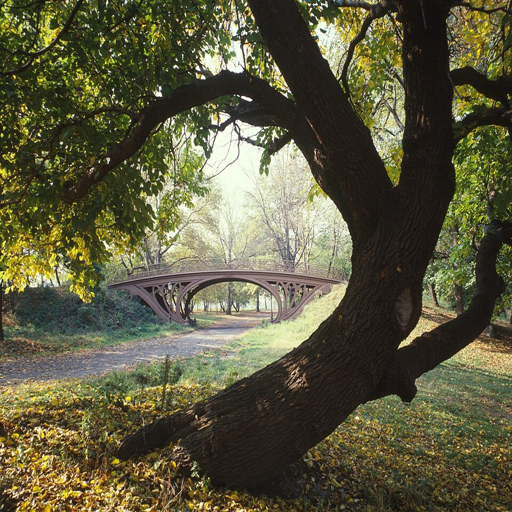

In [9]:
from pathlib import Path
from PIL import Image
from IPython.display import display

test_dir = Path("/content/central_park_test")
test_dir.mkdir(parents=True, exist_ok=True)

# JPG uploaded to Colab's /content/ directory
uploaded_path = Path(
    "/content/Central_Park_New_York_City_New_York_23_cropped.jpg"
)

assert uploaded_path.exists(), f"Image not found: {uploaded_path}"

real_image = Image.open(uploaded_path).convert("RGB")

# Save to our test directory
real_path = test_dir / "real_central_park.jpg"
real_image.save(real_path, quality=95)

print("Loaded:", uploaded_path)
print("Saved:", real_path)
print("Image size:", real_image.size)

display(real_image.resize((512, 512)))

[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/685 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


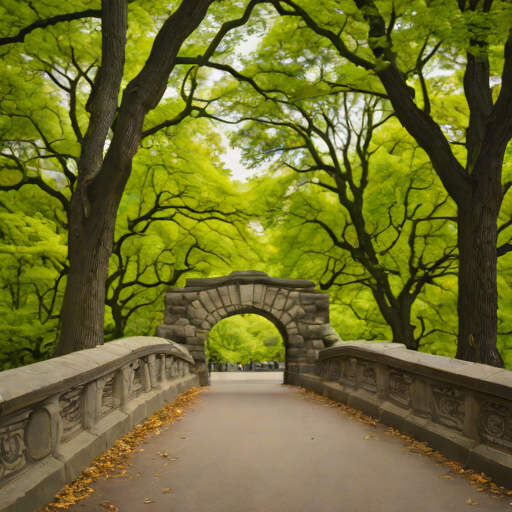

  0%|          | 0/4 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


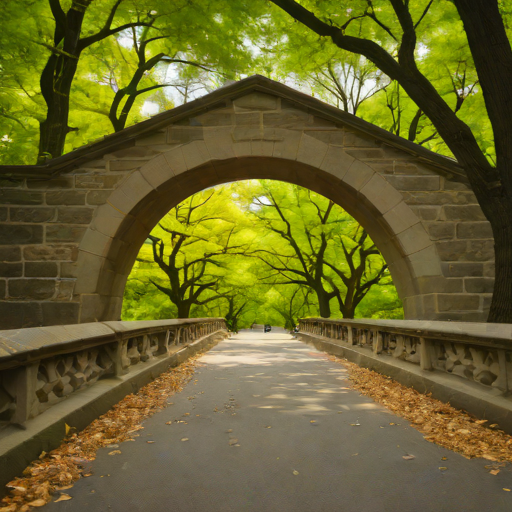

In [10]:
import torch
from diffusers import AutoPipelineForText2Image
from IPython.display import display

pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sdxl-turbo",
    torch_dtype=torch.float16,
    variant="fp16"
).to("cuda")

prompt = (
    "Landscape photograph of Central Park in New York City, "
    "a historic Gothic stone arch bridge spanning a quiet bridle path, "
    "mature trees, no people, no text"
)

fake_paths = []

for i in range(2):
    image = pipe(
        prompt=prompt,
        num_inference_steps=4,
        guidance_scale=0.0,
        height=512,
        width=512,
        generator=torch.Generator(device="cuda").manual_seed(42 + i)
    ).images[0]

    path = test_dir / f"fake_central_park_{i+1}.jpg"
    image.save(path, quality=95)
    fake_paths.append(path)

    display(image)

del pipe
torch.cuda.empty_cache()

In [11]:
from pathlib import Path
import pandas as pd
from imgcompliance.detector import Detector

checkpoint = Path("/content/detector_head.pt")
assert checkpoint.exists(), "Checkpoint missing. Run or restore A2 training first."

# Load existing trained detector
detector = Detector(checkpoint=checkpoint)

test_images = [
    (real_path, "real"),
    (fake_paths[0], "ai"),
    (fake_paths[1], "ai")
]

results = []

for image_path, actual in test_images:
    prediction = detector.predict(image_path)

    results.append({
        "image": image_path.name,
        "actual": actual,
        "predicted": prediction["label"],
        "ai_score": round(prediction["prob"], 4),
        "correct": actual == prediction["label"]
    })

results_df = pd.DataFrame(results)
display(results_df)

print(f"Correct: {results_df['correct'].sum()}/3")

,image,actual,predicted,ai_score,correct
0,real_central_park.jpg,real,real,0.4309,True
1,fake_central_park_1.jpg,ai,ai,0.6367,True
2,fake_central_park_2.jpg,ai,ai,0.5344,True


Correct: 3/3
